<a href="https://colab.research.google.com/github/Tejaswini2028/CSA4703-Deep-Learning/blob/main/11%20to%2020_lab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

170498071/170498071 ━━━━━━━━━━━━━━━━━━━━ 87s 1us/step
Epoch 1/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 57s 89ms/step - accuracy: 0.4392 - loss: 1.5580 - val_accuracy: 0.5205 - val_loss: 1.3313
Epoch 2/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 54s 87ms/step - accuracy: 0.5753 - loss: 1.2046 - val_accuracy: 0.5855 - val_loss: 1.1714
Epoch 3/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 53s 84ms/step - accuracy: 0.6295 - loss: 1.0603 - val_accuracy: 0.6305 - val_loss: 1.0514
Epoch 4/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 55s 87ms/step - accuracy: 0.6663 - loss: 0.9640 - val_accuracy: 0.6445 - val_loss: 1.0261
Epoch 5/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 82s 88ms/step - accuracy: 0.6902 - loss: 0.8941 - val_accuracy: 0.6736 - val_loss: 0.9448
Epoch 6/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 57s 90ms/step - accuracy: 0.7150 - loss: 0.8262 - val_accuracy: 0.6681 - val_loss: 0.9448
Epoch 7/10
625/625 ━━━━━━━━━━━━━━━━━━━━ 60s 97ms/step - accuracy: 0.7334 - loss: 0.7664 - val_accuracy: 0.6859 - val_loss: 0.9211
Epoch 8/10
625/625 ━━━━━━━━━━━━━━━━━

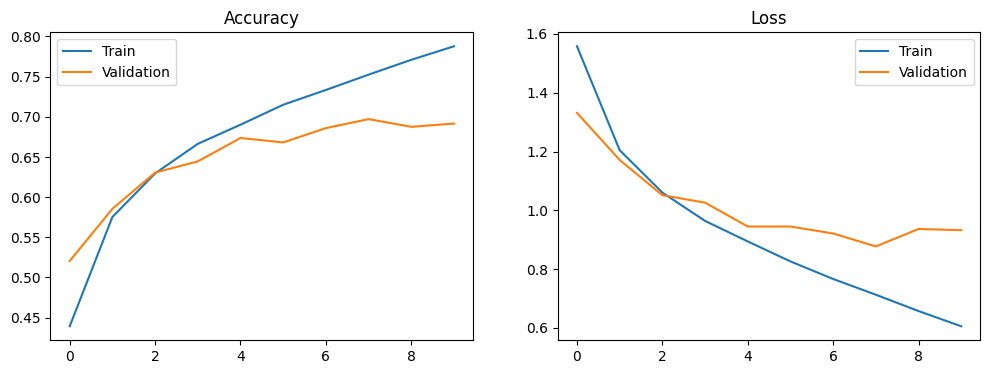

313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 18ms/step


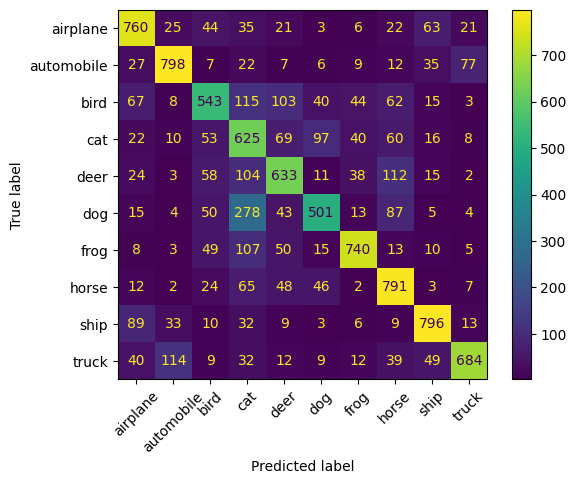

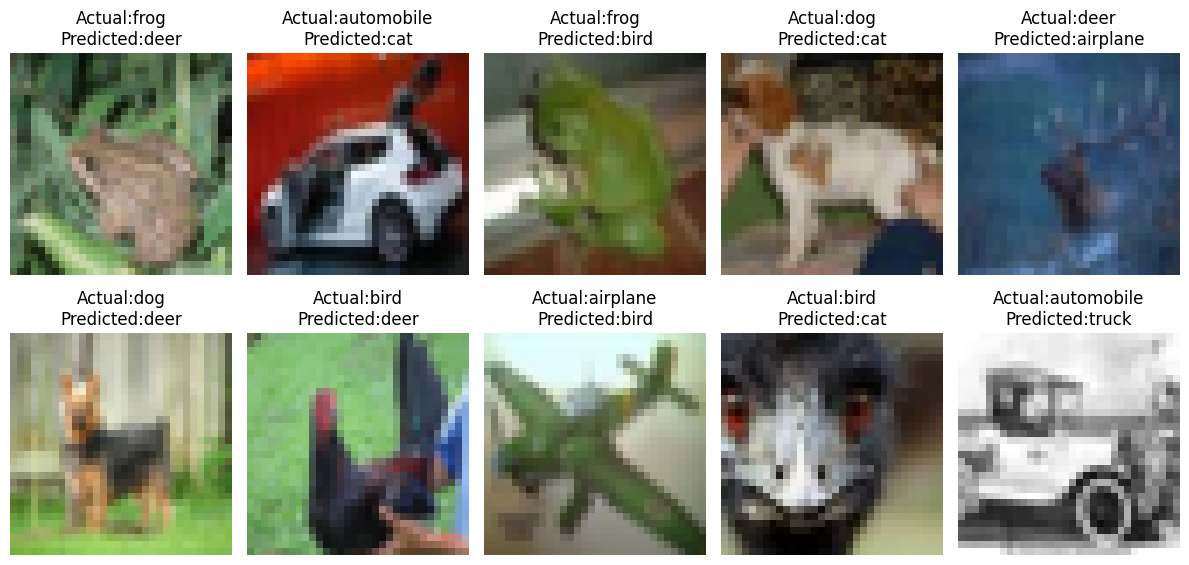

AttributeError: The layer sequential_1 has never been called and thus has no defined input.

In [ ]:

#EXPERIMENT -11


import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix,ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split
(x,y),(xt,yt)=tf.keras.datasets.cifar10.load_data()
x=x.astype("float32")/255.0
xt=xt.astype("float32")/255.0
y=tf.keras.utils.to_categorical(y,10)
yt=tf.keras.utils.to_categorical(yt,10)
x,xv,y,yv=train_test_split(x,y,test_size=0.2,random_state=42)
model=tf.keras.Sequential([tf.keras.layers.Input(shape=(32,32,3)),tf.keras.layers.Conv2D(32,3,activation="relu"),tf.keras.layers.MaxPooling2D(),tf.keras.layers.Conv2D(64,3,activation="relu"),tf.keras.layers.MaxPooling2D(),tf.keras.layers.Flatten(),tf.keras.layers.Dense(128,activation="relu"),tf.keras.layers.Dense(10,activation="softmax")])
model.compile(optimizer="adam",loss="categorical_crossentropy",metrics=["accuracy"])
history=model.fit(x,y,epochs=10,batch_size=64,validation_data=(xv,yv))
loss,accuracy=model.evaluate(xt,yt)
print("Test Accuracy:",accuracy)
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(history.history["accuracy"])
plt.plot(history.history["val_accuracy"])
plt.title("Accuracy")
plt.legend(["Train","Validation"])
plt.subplot(1,2,2)
plt.plot(history.history["loss"])
plt.plot(history.history["val_loss"])
plt.title("Loss")
plt.legend(["Train","Validation"])
plt.show()
pred=np.argmax(model.predict(xt),axis=1)
true=np.argmax(yt,axis=1)
classes=["airplane","automobile","bird","cat","deer","dog","frog","horse","ship","truck"]
cm=confusion_matrix(true,pred)
ConfusionMatrixDisplay(cm,display_labels=classes).plot(xticks_rotation=45)
plt.show()
wrong=np.where(pred!=true)[0][:10]
plt.figure(figsize=(12,6))
for i,index in enumerate(wrong):
    plt.subplot(2,5,i+1)
    plt.imshow(xt[index])
    plt.title("Actual:"+classes[true[index]]+"\nPredicted:"+classes[pred[index]])
    plt.axis("off")
plt.tight_layout()
plt.show()
feature_model=tf.keras.Model(inputs=model.input,outputs=model.layers[0].output)
features=feature_model.predict(xt[:1])
plt.figure(figsize=(12,6))
for i in range(min(16,features.shape[-1])):
    plt.subplot(4,4,i+1)
    plt.imshow(features[0,:,:,i],cmap="viridis")
    plt.axis("off")
plt.show()


Experiment 12 – CNN Architecture and Hyperparameter Comparison

Testing: (2, 3, 32, True, True, 0.001, 64)
Accuracy: 0.466 Parameters: 545482 Time: 119.3 seconds
Testing: (3, 3, 32, True, True, 0.001, 64)
Accuracy: 0.5007 Parameters: 357706 Time: 166.62 seconds
Testing: (4, 3, 16, True, False, 0.001, 64)
Accuracy: 0.4883 Parameters: 164394 Time: 56.5 seconds
Testing: (2, 5, 32, False, True, 0.001, 64)
Accuracy: 0.4677 Parameters: 579786 Time: 187.27 seconds
Testing: (3, 5, 16, False, False, 0.0005, 128)
Accuracy: 0.4247 Parameters: 197802 Time: 97.14 seconds
Testing: (3, 3, 32, False, True, 0.0005, 128)
Accuracy: 0.1087 Parameters: 357706 Time: 116.08 seconds
Testing: (4, 3, 16, False, True, 0.001, 128)
Accuracy: 0.1413 Parameters: 165354 Time: 84.64 seconds
Testing: (2, 5, 16, True, False, 0.0001, 32)
Accuracy: 0.4403 Parameters: 277610 Time: 88.13 seconds

Experiment Results
 Conv Layers  Filter Size  Filters Pooling  Batch Normalization  Learning Rate  Batch Size  Accuracy  Parameters  Training Time
           2            3       32     Max    

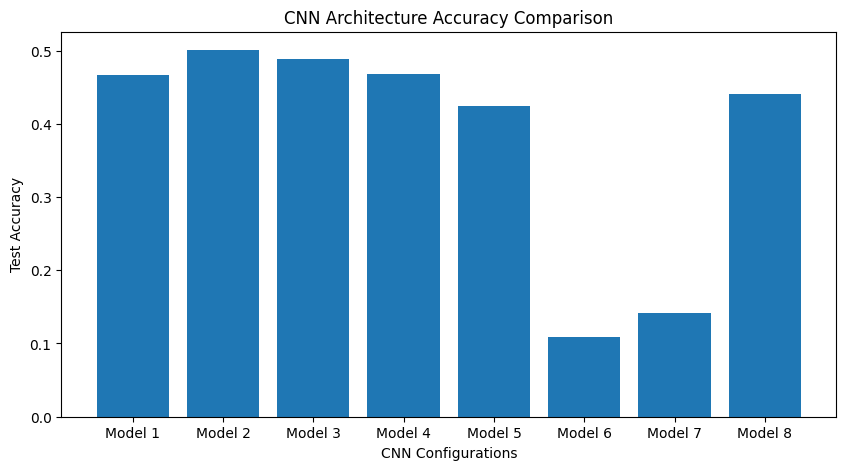

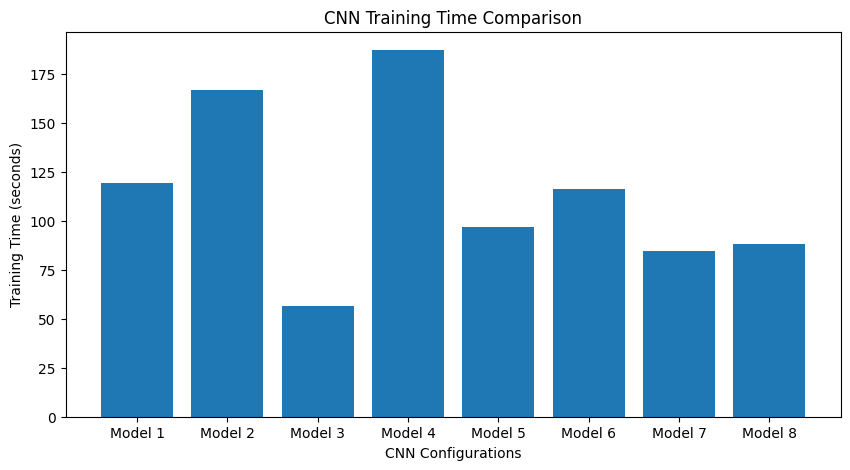

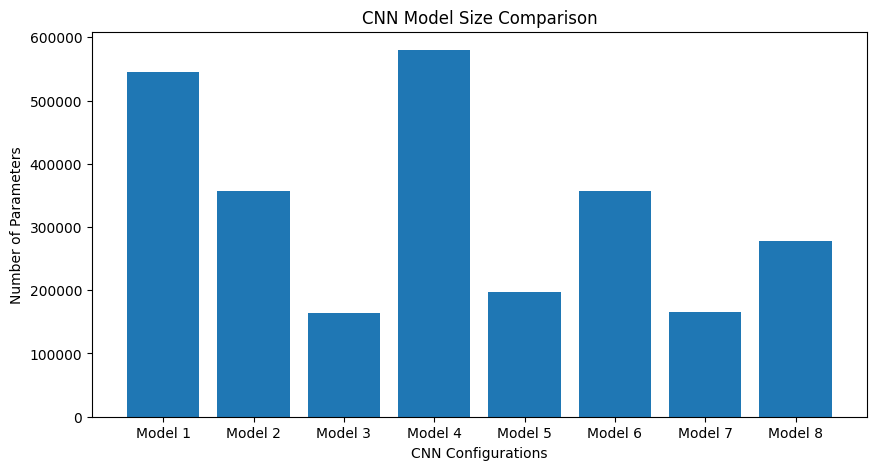


Best Configuration:
Conv Layers                     3
Filter Size                     3
Filters                        32
Pooling                       Max
Batch Normalization          True
Learning Rate               0.001
Batch Size                     64
Accuracy                 0.500667
Parameters                 357706
Training Time          166.622656
Name: 1, dtype: object


In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
import time
np.random.seed(42)
tf.random.set_seed(42)
(x_train,y_train),(x_test,y_test)=tf.keras.datasets.cifar10.load_data()
x_train=x_train.astype("float32")/255.0
x_test=x_test.astype("float32")/255.0
x_train=x_train[:15000]
y_train=y_train[:15000]
x_test=x_test[:3000]
y_test=y_test[:3000]
def build_model(n,k,f,p,b,lr):
    model=tf.keras.Sequential()
    model.add(tf.keras.layers.Input(shape=(32,32,3)))
    for i in range(n):
        model.add(tf.keras.layers.Conv2D(f*(2**i),kernel_size=(k,k),padding="same",activation="relu"))
        if b:
            model.add(tf.keras.layers.BatchNormalization())
        if p:
            model.add(tf.keras.layers.MaxPooling2D(pool_size=(2,2)))
        else:
            model.add(tf.keras.layers.AveragePooling2D(pool_size=(2,2)))
    model.add(tf.keras.layers.Flatten())
    model.add(tf.keras.layers.Dense(128,activation="relu"))
    model.add(tf.keras.layers.Dense(10,activation="softmax"))
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=lr),loss="sparse_categorical_crossentropy",metrics=["accuracy"])
    return model
configs=[
    (2,3,32,True,True,0.001,64),
    (3,3,32,True,True,0.001,64),
    (4,3,16,True,False,0.001,64),
    (2,5,32,False,True,0.001,64),
    (3,5,16,False,False,0.0005,128),
    (3,3,32,False,True,0.0005,128),
    (4,3,16,False,True,0.001,128),
    (2,5,16,True,False,0.0001,32)
]

results=[]
for c in configs:
    n,k,f,p,b,lr,bs=c
    print("Testing:",c)
    model=build_model(n,k,f,p,b,lr)
    start=time.time()
    history=model.fit(x_train,y_train,epochs=3,batch_size=bs,validation_split=0.2,verbose=0)
    training_time=time.time()-start
    loss,accuracy=model.evaluate(x_test,y_test,verbose=0)
    results.append([n,k,f,"Max" if p else "Average",b,lr,bs,accuracy,model.count_params(),training_time])
    print("Accuracy:",round(accuracy,4),"Parameters:",model.count_params(),"Time:",round(training_time,2),"seconds")
df=pd.DataFrame(results,columns=["Conv Layers","Filter Size","Filters","Pooling","Batch Normalization","Learning Rate","Batch Size","Accuracy","Parameters","Training Time"])
print("\nExperiment Results")
print(df.to_string(index=False))
plt.figure(figsize=(10,5))
plt.bar(range(len(df)),df["Accuracy"])
plt.xticks(range(len(df)),["Model "+str(i+1) for i in range(len(df))])
plt.xlabel("CNN Configurations")
plt.ylabel("Test Accuracy")
plt.title("CNN Architecture Accuracy Comparison")
plt.show()
plt.figure(figsize=(10,5))
plt.bar(range(len(df)),df["Training Time"])
plt.xticks(range(len(df)),["Model "+str(i+1) for i in range(len(df))])
plt.xlabel("CNN Configurations")
plt.ylabel("Training Time (seconds)")
plt.title("CNN Training Time Comparison")
plt.show()
plt.figure(figsize=(10,5))
plt.bar(range(len(df)),df["Parameters"])
plt.xticks(range(len(df)),["Model "+str(i+1) for i in range(len(df))])
plt.xlabel("CNN Configurations")
plt.ylabel("Number of Parameters")
plt.title("CNN Model Size Comparison")
plt.show()
best=df.loc[df["Accuracy"].idxmax()]
print("\nBest Configuration:")
print(best)


Experiment 13 – Sequential Dataset Preparation and RNN Prediction


/tmp/ipykernel_846/1035197906.py:9: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df=df.interpolate().fillna(method="bfill")


Epoch 1/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 2s 32ms/step - loss: 0.0736 - val_loss: 0.0063
Epoch 2/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 21ms/step - loss: 0.0040 - val_loss: 0.0035
Epoch 3/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0025 - val_loss: 0.0024
Epoch 4/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0022 - val_loss: 0.0024
Epoch 5/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 15ms/step - loss: 0.0020 - val_loss: 0.0017
Epoch 6/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0018 - val_loss: 0.0018
Epoch 7/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0018 - val_loss: 0.0020
Epoch 8/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0018 - val_loss: 0.0017
Epoch 9/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0016 - val_loss: 0.0014
Epoch 10/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0015 - val_loss: 0.0013
Epoch 11/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0015 - val_loss: 0.0014
Epoch 12/20
20/20 ━━━━━━━━━━━━━━━━━━━━ 0s 9ms/step - loss: 0.0015 -

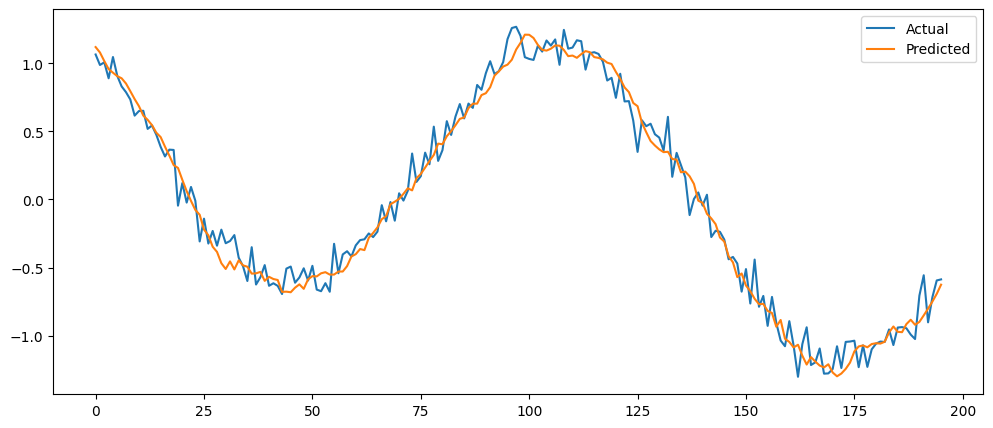

In [ ]:
import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error,mean_squared_error
data=np.sin(np.arange(1000)*0.05)+0.5*np.sin(np.arange(1000)*0.01)+np.random.normal(0,0.1,1000)
df=pd.DataFrame({"Demand":data})
df=df.interpolate().fillna(method="bfill")
scaler=MinMaxScaler()
series=scaler.fit_transform(df[["Demand"]])
window=24
X=[]
Y=[]
for i in range(len(series)-window):
    X.append(series[i:i+window])
    Y.append(series[i+window])
X=np.array(X)
Y=np.array(Y)
split=int(len(X)*0.8)
X_train,X_test=X[:split],X[split:]
y_train,y_test=Y[:split],Y[split:]
model=tf.keras.Sequential([tf.keras.layers.Input(shape=(window,1)),tf.keras.layers.SimpleRNN(50,activation="tanh"),tf.keras.layers.Dense(1)])
model.compile(optimizer="adam",loss="mse")
model.fit(X_train,y_train,epochs=20,batch_size=32,validation_split=0.2)
pred=model.predict(X_test)
actual=scaler.inverse_transform(y_test)
pred=scaler.inverse_transform(pred)
print("MAE:",mean_absolute_error(actual,pred))
print("RMSE:",np.sqrt(mean_squared_error(actual,pred)))
plt.figure(figsize=(12,5))
plt.plot(actual,label="Actual")
plt.plot(pred,label="Predicted")
plt.legend()
plt.show()

Experiment 14 – Unfolded RNN Architecture Visualization

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 156ms/step
Input Weights: [[-0.26536083  0.5521885   0.46723115]]
Recurrent Weights: [[ 0.60522354  0.76760477  0.2109203 ]
 [ 0.24133046  0.07556728 -0.96749634]
 [-0.75859356  0.63645303 -0.13951136]]
Output Weights: [[-0.558574  ]
 [-0.0186131 ]
 [ 0.68190074]]
Manual Hidden States:
 [[-0.25930283  0.50215866  0.43595943]
 [-0.71492574  0.8398751   0.32131438]
 [-0.8537521   0.87999686  0.37437192]
 [-0.92882746  0.95251028  0.65569726]
 [-0.9735669   0.9875698   0.81006559]]
Keras Hidden States:
 [[-0.25930282  0.50215864  0.43595946]
 [-0.71492577  0.8398751   0.3213144 ]
 [-0.8537521   0.87999684  0.37437198]
 [-0.92882746  0.9525103   0.6556973 ]
 [-0.97356683  0.9875698   0.8100656 ]]


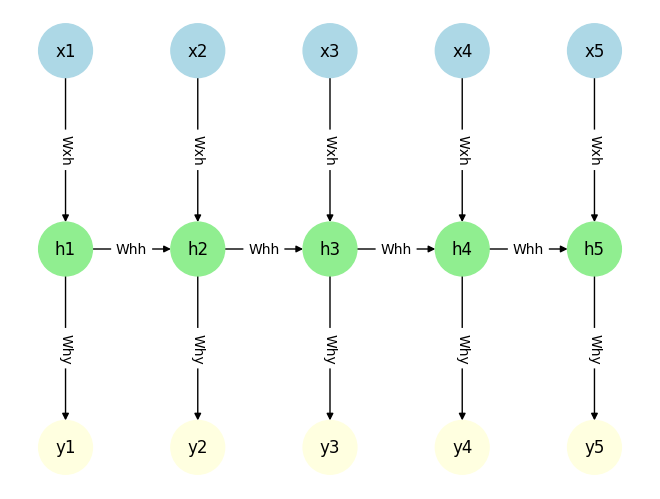

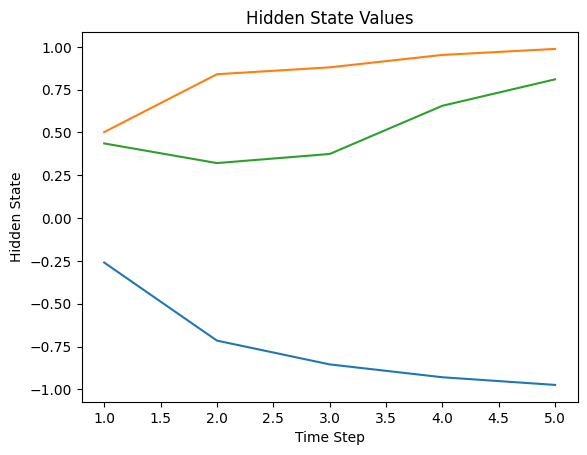

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import networkx as nx
model=tf.keras.Sequential([tf.keras.layers.Input(shape=(5,1)),tf.keras.layers.SimpleRNN(3,return_sequences=True),tf.keras.layers.Dense(1)])
model.compile(optimizer="adam",loss="mse")
x=np.array([[[1.],[2.],[3.],[4.],[5.]]])
y=model.predict(x)
rnn=model.layers[0]
Wx,Wh,b=rnn.get_weights()
dense=model.layers[1]
Wy,by=dense.get_weights()
h=np.zeros((1,3))
states=[]
for i in range(5):
    h=np.tanh(x[:,i,:]@Wx+h@Wh+b)
    states.append(h[0].copy())
manual=np.array(states)
print("Input Weights:",Wx)
print("Recurrent Weights:",Wh)
print("Output Weights:",Wy)
print("Manual Hidden States:\n",manual)
print("Keras Hidden States:\n",model.layers[0](x).numpy()[0])
G=nx.DiGraph()
for i in range(5):
    G.add_node("x"+str(i+1),color="lightblue")
    G.add_node("h"+str(i+1),color="lightgreen")
    G.add_node("y"+str(i+1),color="lightyellow")
    G.add_edge("x"+str(i+1),"h"+str(i+1),label="Wxh")
    G.add_edge("h"+str(i+1),"y"+str(i+1),label="Why")
    if i>0:
        G.add_edge("h"+str(i),"h"+str(i+1),label="Whh")
pos={}
for i in range(5):
    pos["x"+str(i+1)]=(i,2)
    pos["h"+str(i+1)]=(i,1)
    pos["y"+str(i+1)]=(i,0)
colors=[G.nodes[n]["color"] for n in G.nodes()]
nx.draw(G,pos,with_labels=True,node_color=colors,node_size=1500,arrows=True)
nx.draw_networkx_edge_labels(G,pos,edge_labels=nx.get_edge_attributes(G,"label"))
plt.show()
plt.plot(range(1,6),manual)
plt.xlabel("Time Step")
plt.ylabel("Hidden State")
plt.title("Hidden State Values")
plt.show()


Experiment 15 – BPTT Flow and Gradient Analysis



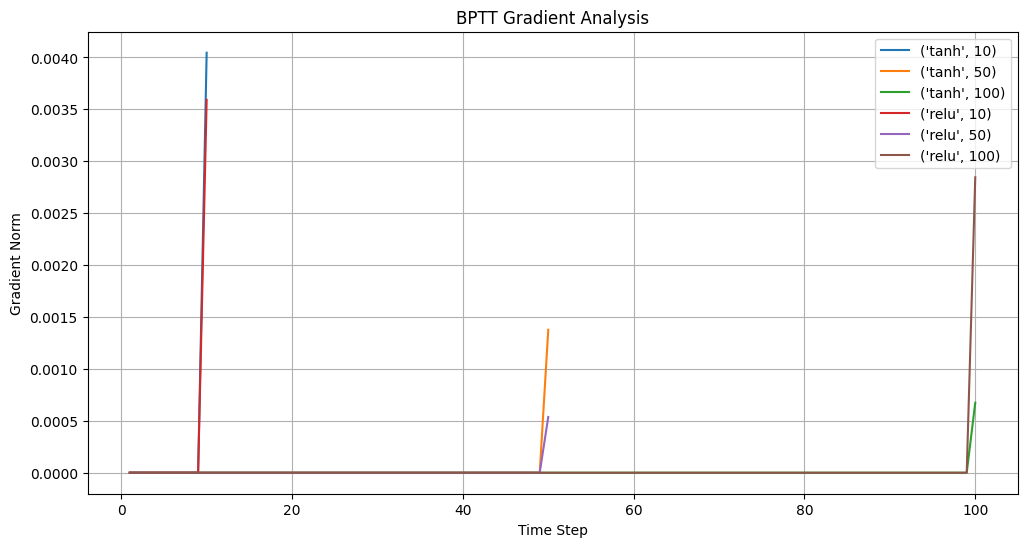

('tanh', 10) Initial Gradient: 0.0 Final Gradient: 0.004045193
('tanh', 50) Initial Gradient: 0.0 Final Gradient: 0.0013769026
('tanh', 100) Initial Gradient: 0.0 Final Gradient: 0.0006742855
('relu', 10) Initial Gradient: 0.0 Final Gradient: 0.0035909337
('relu', 50) Initial Gradient: 0.0 Final Gradient: 0.0005369043
('relu', 100) Initial Gradient: 0.0 Final Gradient: 0.0028453844


In [ ]:

import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt

np.random.seed(42)
tf.random.set_seed(42)

data=np.sin(np.arange(1500)*0.02)+np.random.normal(0,0.05,1500)
data=(data-data.min())/(data.max()-data.min())

lengths=[10,50,100]
activations=["tanh","relu"]
results={}

for activation in activations:
    for length in lengths:
        X=[]
        Y=[]
        for i in range(len(data)-length):
            X.append(data[i:i+length])
            Y.append(data[i+length])

        X=tf.constant(np.array(X[:500]).reshape(-1,length,1),dtype=tf.float32)
        Y=tf.constant(np.array(Y[:500]).reshape(-1,1),dtype=tf.float32)

        rnn=tf.keras.layers.SimpleRNN(32,activation=activation,return_sequences=True)
        dense=tf.keras.layers.Dense(1)
        optimizer=tf.keras.optimizers.Adam(0.001)

        for epoch in range(3):
            with tf.GradientTape() as tape:
                states=rnn(X,training=True)
                predictions=dense(states[:,-1,:])
                loss=tf.reduce_mean(tf.square(Y-predictions))
            gradients=tape.gradient(loss,rnn.trainable_variables+dense.trainable_variables)
            optimizer.apply_gradients(zip(gradients,rnn.trainable_variables+dense.trainable_variables))

        with tf.GradientTape() as tape:
            states=rnn(X,training=False)
            tape.watch(states)
            predictions=dense(states[:,-1,:])
            loss=tf.reduce_mean(tf.square(Y-predictions))

        gradients=tape.gradient(loss,states)
        norms=tf.norm(gradients,axis=2).numpy().mean(axis=0)
        results[(activation,length)]=norms

plt.figure(figsize=(12,6))
for key,value in results.items():
    plt.plot(range(1,len(value)+1),value,label=str(key))
plt.xlabel("Time Step")
plt.ylabel("Gradient Norm")
plt.title("BPTT Gradient Analysis")
plt.legend()
plt.grid()
plt.show()

for key,value in results.items():
    print(key,"Initial Gradient:",value[0],"Final Gradient:",value[-1])


Experiment 16 – LSTM and RNN Performance Comparison

1/7 ━━━━━━━━━━━━━━━━━━━━ 0s 140ms/step

7/7 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step
7/7 ━━━━━━━━━━━━━━━━━━━━ 1s 52ms/step
    Model  Training Loss  Validation Loss      MAE      RMSE     MAPE  Training Time
SimpleRNN       0.038411         0.045495 3.448949  4.161504 2.711224       8.068161
     LSTM       0.045746         0.101302 9.642908 12.169355 7.081280      10.881072


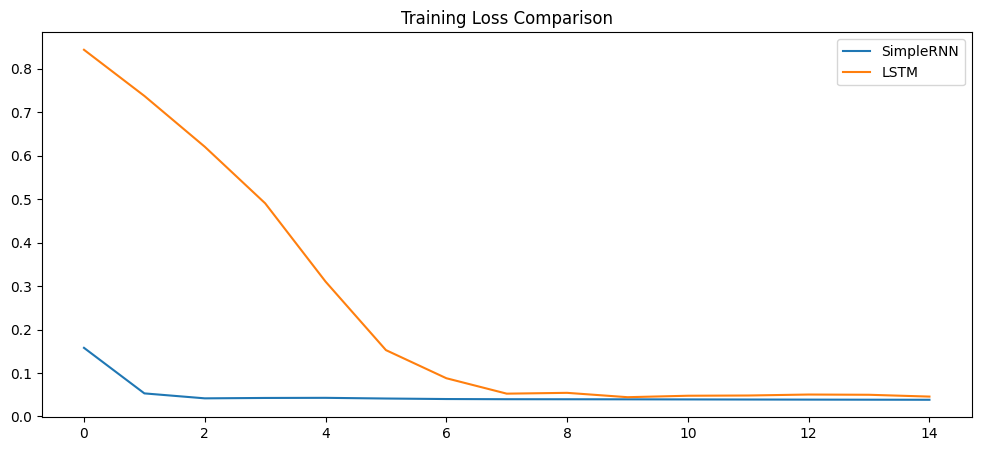

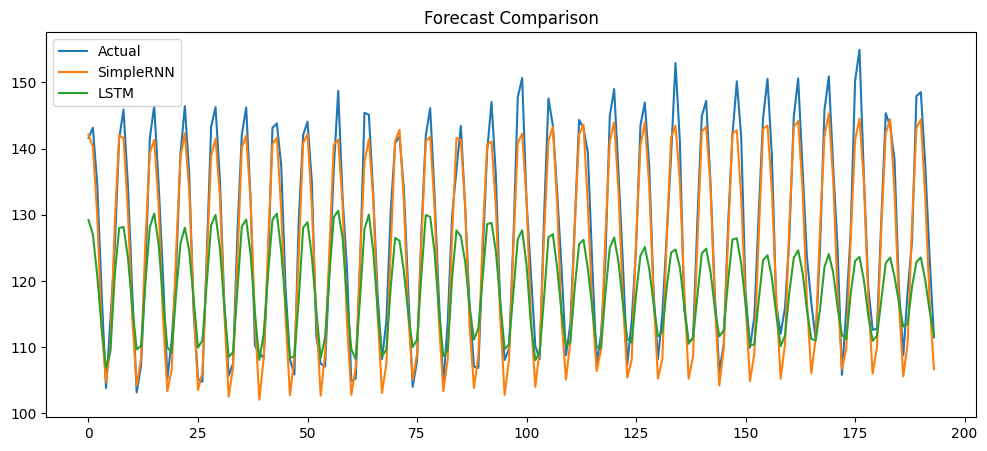

In [ ]:
import tensorflow as tf
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time
from sklearn.metrics import mean_absolute_error,mean_squared_error
data=100+20*np.sin(np.arange(1000)*2*np.pi/7)+np.arange(1000)*0.03+np.random.normal(0,3,1000)
data=data.reshape(-1,1)
mean=data.mean()
std=data.std()
data=(data-mean)/std
X=[]
Y=[]
for i in range(len(data)-30):
    X.append(data[i:i+30])
    Y.append(data[i+30])
X=np.array(X)
Y=np.array(Y)
split=int(len(X)*0.8)
X_train,X_test=X[:split],X[split:]
y_train,y_test=Y[:split],Y[split:]
models={}
results=[]
for name,layer in [("SimpleRNN",tf.keras.layers.SimpleRNN(50)),("LSTM",tf.keras.layers.LSTM(50))]:
    model=tf.keras.Sequential([tf.keras.layers.Input(shape=(30,1)),layer,tf.keras.layers.Dense(1)])
    model.compile(optimizer="adam",loss="mse")
    start=time.time()
    history=model.fit(X_train,y_train,epochs=15,batch_size=32,validation_split=0.2,verbose=0)
    duration=time.time()-start
    pred=model.predict(X_test)
    actual=y_test*std+mean
    predicted=pred*std+mean
    mae=mean_absolute_error(actual,predicted)
    rmse=np.sqrt(mean_squared_error(actual,predicted))
    mape=np.mean(np.abs((actual-predicted)/(actual+1e-8)))*100
    models[name]=(model,history,predicted)
    results.append([name,history.history["loss"][-1],history.history["val_loss"][-1],mae,rmse,mape,duration])
df=pd.DataFrame(results,columns=["Model","Training Loss","Validation Loss","MAE","RMSE","MAPE","Training Time"])
print(df.to_string(index=False))
plt.figure(figsize=(12,5))
for name,(model,history,pred) in models.items():
    plt.plot(history.history["loss"],label=name)
plt.legend()
plt.title("Training Loss Comparison")
plt.show()
plt.figure(figsize=(12,5))
plt.plot(actual,label="Actual")
for name,(model,history,pred) in models.items():
    plt.plot(pred,label=name)
plt.legend()
plt.title("Forecast Comparison")
plt.show()

Experiment 17 – RNN Gradient Analysis and Gradient Clipping

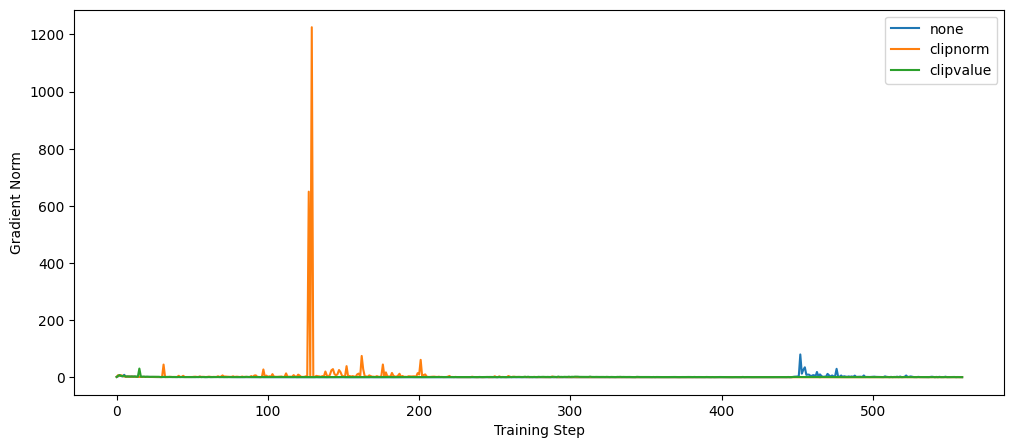

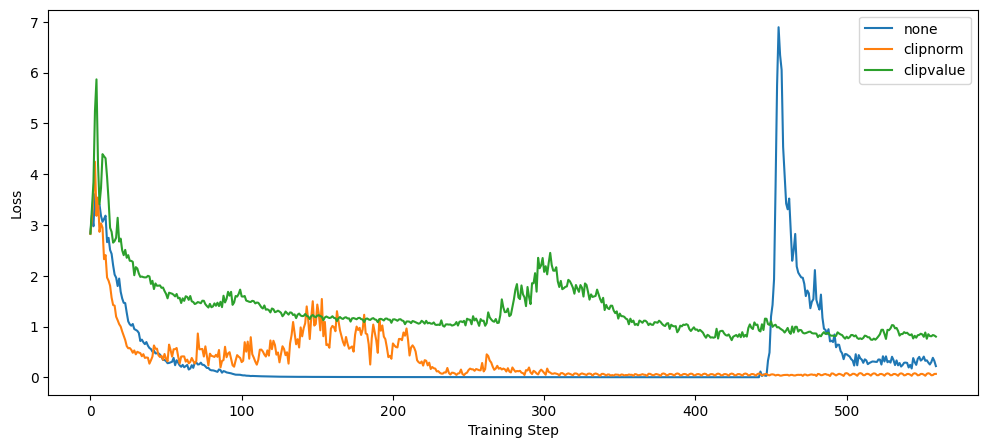

none Maximum Gradient: 79.75281524658203 Final Loss: 0.22068850696086884
clipnorm Maximum Gradient: 1225.431396484375 Final Loss: 0.06698741763830185
clipvalue Maximum Gradient: 30.373559951782227 Final Loss: 0.8011658787727356


In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
text="machine learning and artificial intelligence are transforming the world "
text=text*100
chars=sorted(set(text))
char_to_int={c:i for i,c in enumerate(chars)}
data=np.array([char_to_int[c] for c in text])
seq_length=20
X=[]
Y=[]
for i in range(len(data)-seq_length):
    X.append(data[i:i+seq_length])
    Y.append(data[i+seq_length])
X=np.array(X)
Y=np.array(Y)
def train_model(mode):
    model=tf.keras.Sequential([tf.keras.layers.Embedding(len(chars),32),tf.keras.layers.SimpleRNN(64),tf.keras.layers.Dense(len(chars))])
    if mode=="none":
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.1)
    elif mode=="clipnorm":
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.1,clipnorm=1.0)
    else:
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.1,clipvalue=0.5)
    loss_fn=tf.keras.losses.SparseCategoricalCrossentropy(from_logits=True)
    norms=[]
    losses=[]
    for epoch in range(5):
        for i in range(0,len(X)-64,64):
            xb=X[i:i+64]
            yb=Y[i:i+64]
            with tf.GradientTape() as tape:
                pred=model(xb,training=True)
                loss=loss_fn(yb,pred)
            gradients=tape.gradient(loss,model.trainable_variables)
            norm=tf.linalg.global_norm(gradients)
            norms.append(float(norm))
            losses.append(float(loss))
            optimizer.apply_gradients(zip(gradients,model.trainable_variables))
            if not np.isfinite(float(loss)):
                break
    return norms,losses
results={}
for mode in ["none","clipnorm","clipvalue"]:
    results[mode]=train_model(mode)
plt.figure(figsize=(12,5))
for mode,(norms,losses) in results.items():
    plt.plot(norms,label=mode)
plt.xlabel("Training Step")
plt.ylabel("Gradient Norm")
plt.legend()
plt.show()
plt.figure(figsize=(12,5))
for mode,(norms,losses) in results.items():
    plt.plot(losses,label=mode)
plt.xlabel("Training Step")
plt.ylabel("Loss")
plt.legend()
plt.show()
for mode,(norms,losses) in results.items():
    print(mode,"Maximum Gradient:",np.max(norms),"Final Loss:",losses[-1])

Experiment 18 – RNN, LSTM and GRU Hyperparameter Experimentation

In [ ]:
!pip install -q keras-tuner

In [ ]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
import keras_tuner as kt
import time
from tensorflow.keras.preprocessing.sequence import pad_sequences
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.text import Tokenizer
vocab_size=10000
max_length=200
(x_train,y_train),(x_test,y_test)=imdb.load_data(num_words=vocab_size)
x_train=pad_sequences(x_train,maxlen=max_length)
x_test=pad_sequences(x_test,maxlen=max_length)
def build_model(hp):
    model=tf.keras.Sequential()
    model.add(tf.keras.layers.Embedding(vocab_size,hp.Choice("embedding",[32,64,128]),input_length=max_length))
    cell=hp.Choice("cell",["RNN","LSTM","GRU"])
    units=hp.Choice("units",[32,64,128])
    if cell=="RNN":
        layer=tf.keras.layers.SimpleRNN
    elif cell=="LSTM":
        layer=tf.keras.layers.LSTM
    else:
        layer=tf.keras.layers.GRU
    model.add(layer(units,return_sequences=hp.Boolean("extra_layer")))
    if hp.Boolean("extra_layer"):
        model.add(layer(units))
    model.add(tf.keras.layers.Dropout(hp.Float("dropout",0.2,0.5,step=0.1)))
    model.add(tf.keras.layers.Dense(1,activation="sigmoid"))
    model.compile(optimizer=tf.keras.optimizers.Adam(hp.Choice("learning_rate",[0.001,0.0005,0.0001])),loss="binary_crossentropy",metrics=["accuracy"])
    return model
for cell in ["RNN","LSTM","GRU"]:
    tuner=kt.RandomSearch(build_model,objective="val_accuracy",max_trials=3,overwrite=True,directory="tuner",project_name=cell)
    tuner.search(x_train[:10000],y_train[:10000],epochs=3,batch_size=64,validation_split=0.2,verbose=1,callbacks=[tf.keras.callbacks.LambdaCallback(on_epoch_end=lambda epoch,logs:None)])
    best=tuner.get_best_models(1)[0]
    print(cell,"Best Hyperparameters:",tuner.get_best_hyperparameters(1)[0].values)
    start=time.time()
    loss,accuracy=best.evaluate(x_test[:3000],y_test[:3000],verbose=0)
    duration=time.time()-start
    print("Accuracy:",accuracy)
    print("Parameters:",best.count_params())
    print("Evaluation Time:",duration)

Trial 3 Complete [00h 00m 42s]
val_accuracy: 0.6104999780654907

Best val_accuracy So Far: 0.8345000147819519
Total elapsed time: 00h 03m 28s
GRU Best Hyperparameters: {'embedding': 128, 'cell': 'RNN', 'units': 128, 'extra_layer': True, 'dropout': 0.2, 'learning_rate': 0.0001}
Accuracy: 0.8186666369438171
Parameters: 1345921
Evaluation Time: 5.795737981796265


Experiment 19 – PCA and Explained Variance Analysis

Components for 95% Variance: 29
Scikit-learn Components: 29


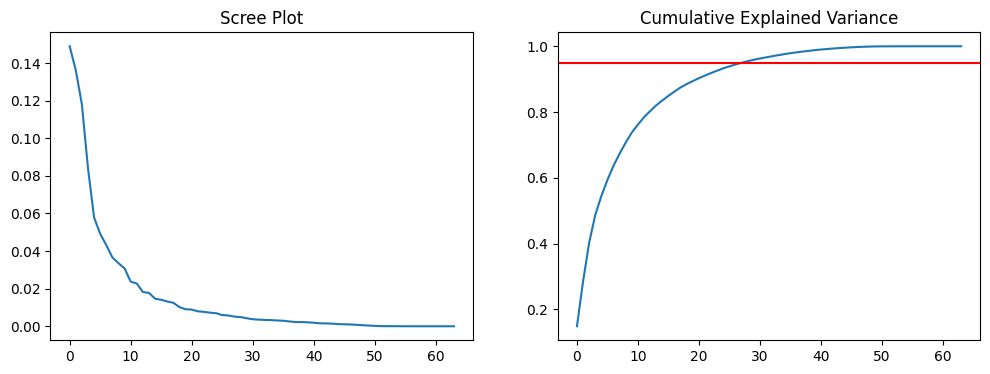

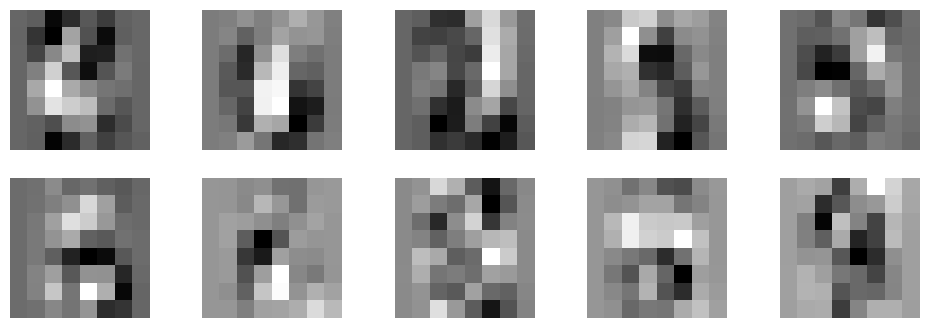

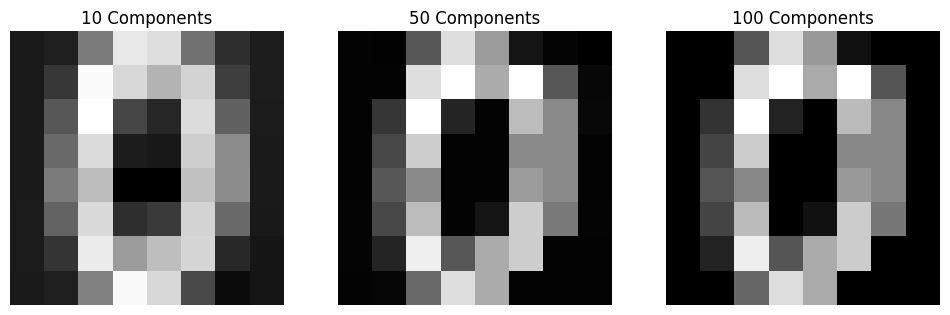

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_digits
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
data=load_digits()
X=data.data
images=data.images
X_mean=np.mean(X,axis=0)
X_centered=X-X_mean
cov=np.cov(X_centered,rowvar=False)
eigenvalues,eigenvectors=np.linalg.eigh(cov)
idx=np.argsort(eigenvalues)[::-1]
eigenvalues=eigenvalues[idx]
eigenvectors=eigenvectors[:,idx]
explained=eigenvalues/eigenvalues.sum()
cumulative=np.cumsum(explained)
components=np.argmax(cumulative>=0.95)+1
print("Components for 95% Variance:",components)
pca=PCA()
transformed=pca.fit_transform(X)
print("Scikit-learn Components:",np.argmax(np.cumsum(pca.explained_variance_ratio_)>=0.95)+1)
plt.figure(figsize=(12,4))
plt.subplot(1,2,1)
plt.plot(explained)
plt.title("Scree Plot")
plt.subplot(1,2,2)
plt.plot(cumulative)
plt.axhline(0.95,color="red")
plt.title("Cumulative Explained Variance")
plt.show()
plt.figure(figsize=(12,4))
for i in range(10):
    plt.subplot(2,5,i+1)
    plt.imshow(eigenvectors[:,i].reshape(8,8),cmap="gray")
    plt.axis("off")
plt.show()
plt.figure(figsize=(12,4))
for i,k in enumerate([10,50,100]):
    p=PCA(n_components=min(k,64))
    reconstructed=p.inverse_transform(p.fit_transform(X))
    plt.subplot(1,3,i+1)
    plt.imshow(reconstructed[0].reshape(8,8),cmap="gray")
    plt.title(str(k)+" Components")
    plt.axis("off")
plt.show()

Experiment 20 – Probabilistic PCA and Reconstruction Analysis

PPCA Model: x = Wz + mu + epsilon
Components: 1 Noise Variance: 0.8222476459973488 Reconstruction Error: 0.6571403186810812
Components: 2 Noise Variance: 0.5935379279071183 Reconstruction Error: 0.3557666339875267
Components: 3 Noise Variance: 0.49928813696847407 Reconstruction Error: 0.1995155395326022
Components: 4 Noise Variance: 0.46106153182118587 Reconstruction Error: 0.09212009405787291
Components: 5 Noise Variance: 0.0 Reconstruction Error: 3.6728257729323822e-31


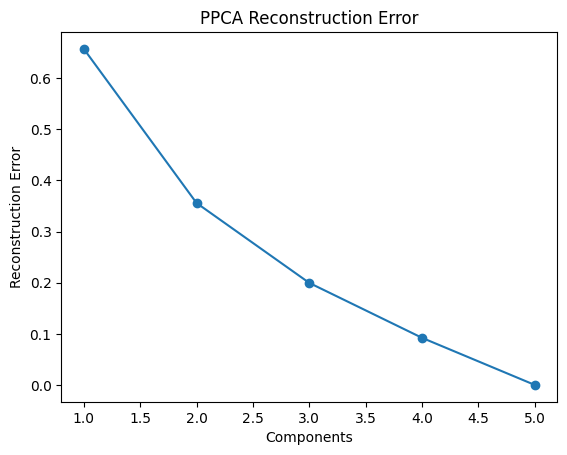

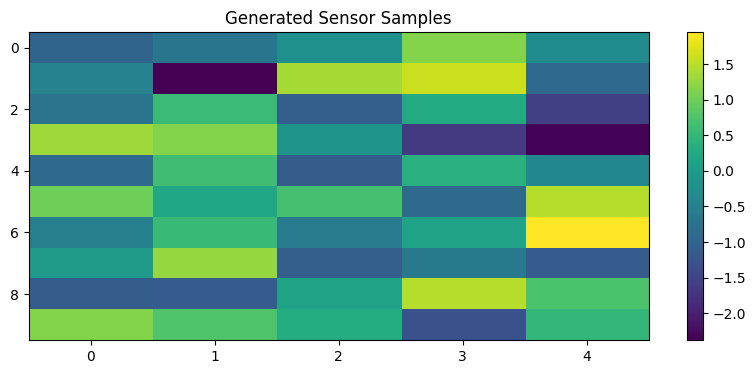

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler
np.random.seed(42)
n=1000
z=np.random.randn(n,3)
W=np.random.randn(3,5)
mu=np.array([20,30,40,50,60])
noise=np.random.normal(0,2,(n,5))
X=z@W+mu+noise
scaler=StandardScaler()
X=scaler.fit_transform(X)
print("PPCA Model: x = Wz + mu + epsilon")
errors=[]
models=[]
for k in range(1,6):
    pca=PCA(n_components=k)
    transformed=pca.fit_transform(X)
    reconstructed=pca.inverse_transform(transformed)
    error=np.mean((X-reconstructed)**2)
    errors.append(error)
    models.append(pca)
    print("Components:",k,"Noise Variance:",pca.noise_variance_,"Reconstruction Error:",error)
plt.plot(range(1,6),errors,marker="o")
plt.xlabel("Components")
plt.ylabel("Reconstruction Error")
plt.title("PPCA Reconstruction Error")
plt.show()
best=models[2]
z_new=np.random.normal(size=(10,3))
W_new=best.components_[:3].T
samples=z_new@W_new.T
plt.figure(figsize=(10,4))
plt.imshow(samples,aspect="auto",cmap="viridis")
plt.title("Generated Sensor Samples")
plt.colorbar()
plt.show()